## 08 - Label validation

Checks the 13 labels of 07 in three parts. Part 1 trains the model of 06 again with other UMAP seeds and measures how many reviews keep their label. Part 2 draws a random sample of reviews for blind coding by hand. Part 3 compares my coding of the sample with the model labels.

Input: `data/processed/trenord_reviews_clean.csv` (Italian reviews only), `data/processed/trenord_reviews_labeled.csv` (from 07) and my coding in `labeling/validation_sample.xlsx`
Output: stability and agreement tables in this notebook, `reports/figures/chart_label_confusion.png`, and three files in `labeling/` (not published, they contain review texts): `validation_sample.xlsx`, `validation_key.csv` and `validation_disagreements.csv`

In [1]:
# --- IMPORTS ---
import os
import warnings

# Two warnings print a local path, so they are hidden before the imports that raise them:
# tqdm warns at import that ipywidgets is missing, and openpyxl warns when it reads the coding
# file, because Excel added an extension to the dropdown that openpyxl cannot read. The labels
# are read anyway.
warnings.filterwarnings("ignore", message="IProgress not found")
warnings.filterwarnings("ignore", message="Data Validation extension is not supported")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from bertopic import BERTopic
from bertopic.representation import MaximalMarginalRelevance
from hdbscan import HDBSCAN
from openpyxl.styles import Alignment
from openpyxl.worksheet.datavalidation import DataValidation
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import cohen_kappa_score
from spacy.lang.it.stop_words import STOP_WORDS as italian_stopwords
from umap import UMAP

# UMAP seeds to train. 42 is the seed of 06, the others are compared with it.
UMAP_SEEDS = [42, 0, 1, 2, 3]
# Reviews drawn from each label (and from EXCLUDE) for the blind coding sample
SAMPLE_PER_LABEL = 14
# Fixed seed for the sample and its order, so the same sample comes out on every run
SAMPLE_SEED = 42
# The two coding files. labeling/ is in .gitignore, because the files contain review texts.
SAMPLE_PATH = "../labeling/validation_sample.xlsx"
KEY_PATH = "../labeling/validation_key.csv"

# Part 3: number of bootstrap resamples and their seed, so the intervals are the same on every run
BOOTSTRAP_RESAMPLES = 2000
BOOTSTRAP_SEED = 42
# The disagreements file holds review texts too, so it also goes to labeling/
DISAGREEMENTS_PATH = "../labeling/validation_disagreements.csv"
CONFUSION_CHART_PATH = "../reports/figures/chart_label_confusion.png"

W1112 17:34:09.079000 36756 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


In [2]:
# --- LOAD DATA ---
# The cleaned reviews, with the same filter as 06: Italian reviews only
clean_df = pd.read_csv("../data/processed/trenord_reviews_clean.csv")
italian_df = clean_df[clean_df["language"] == "it"].copy()

# The label of each review, saved by 07. It also keeps the topic number given by 06.
labeled_df = pd.read_csv("../data/processed/trenord_reviews_labeled.csv")

# The two files must list the same reviews in the same order, because the topics of the new
# runs are compared with the labels position by position.
same_reviews = italian_df["review_id"].tolist() == labeled_df["review_id"].tolist()
assert same_reviews, "The clean and labeled files do not list the same reviews in the same order"

print(f"Italian reviews : {len(italian_df):,}")
print(f"Labeled reviews : {len(labeled_df):,}")
print(f"Same reviews, same order: {same_reviews}")

Italian reviews : 6,951
Labeled reviews : 6,951
Same reviews, same order: True


In [3]:
# --- PREPARE TEXTS ---
# Same text column as 06: text_clean, in natural form for the embeddings.
# BERTopic cannot handle empty strings, so they are replaced by a single space, as in 06.
texts = italian_df["text_clean"].tolist()
for i in range(len(texts)):
    text = texts[i]
    is_valid = isinstance(text, str) and len(text.strip()) > 0
    if not is_valid:
        texts[i] = " "

print(f"Texts prepared: {len(texts):,}")

Texts prepared: 6,951


In [4]:
# --- SENTENCE EMBEDDINGS (computed once) ---
# Same model as 06. The embeddings do not depend on the UMAP seed, so they are computed
# once and passed to every run. 05 showed that this gives the same topics as 06.
embedding_model = SentenceTransformer("paraphrase-multilingual-mpnet-base-v2")
embeddings = embedding_model.encode(texts, show_progress_bar=False)

print(f"Embeddings: {embeddings.shape[0]} reviews x {embeddings.shape[1]} dimensions")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   1%|          | 1/199 [00:00<00:37,  5.29it/s]

Loading weights:   1%|          | 2/199 [00:00<00:28,  6.84it/s]

Loading weights:   2%|▏         | 3/199 [00:00<00:51,  3.81it/s]

Loading weights:   2%|▏         | 4/199 [00:01<01:29,  2.19it/s]

Loading weights:   4%|▎         | 7/199 [00:01<00:36,  5.20it/s]

Loading weights:   5%|▍         | 9/199 [00:02<00:51,  3.69it/s]

Loading weights:  19%|█▉        | 38/199 [00:02<00:05, 27.63it/s]

Loading weights:  24%|██▍       | 48/199 [00:02<00:04, 34.06it/s]

Loading weights: 100%|██████████| 199/199 [00:02<00:00, 74.01it/s]

Embeddings: 6951 reviews x 768 dimensions


In [5]:
# --- FUNCTION TO TRAIN THE MODEL OF 06 WITH A GIVEN UMAP SEED ---
def train_topic_model(umap_random_state):
    # Every setting is the same as in 06; only the UMAP seed changes.
    # Each run gets new model objects, because BERTopic fits them in place.
    umap_model = UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine",
                      random_state=umap_random_state)
    hdbscan_model = HDBSCAN(min_cluster_size=30, metric="euclidean", prediction_data=True)
    vectorizer_model = CountVectorizer(stop_words=list(italian_stopwords), min_df=5, ngram_range=(1, 2))
    representation_model = MaximalMarginalRelevance(diversity=0.3)

    topic_model = BERTopic(
        embedding_model=embedding_model,
        umap_model=umap_model,
        hdbscan_model=hdbscan_model,
        vectorizer_model=vectorizer_model,
        representation_model=representation_model,
        top_n_words=10,
        language="multilingual",
        calculate_probabilities=False,
        verbose=False
    )

    # Passing the embeddings skips the encoding step inside BERTopic
    topics_before, _ = topic_model.fit_transform(texts, embeddings=embeddings)

    # Outliers are reassigned to the closest topic, as in 06
    topics_after = topic_model.reduce_outliers(
        texts,
        topics_before,
        strategy="embeddings",
        threshold=0.0,
        embeddings=embeddings
    )
    return topics_before, topics_after

In [6]:
# --- TRAIN ONE MODEL PER SEED ---
# Only the topic of each review is kept: the stability check needs nothing else.
topics_by_seed = {}
for seed in UMAP_SEEDS:
    topics_before, topics_after = train_topic_model(seed)
    topics_by_seed[seed] = list(topics_after)

    n_topics = len(set(topics_after))
    n_outliers_before = list(topics_before).count(-1)
    print(f"seed {seed:2d}: {n_topics} topics, {n_outliers_before:,} outliers before reduction")

seed 42: 30 topics, 1,601 outliers before reduction


seed  0: 33 topics, 2,023 outliers before reduction


seed  1: 27 topics, 1,264 outliers before reduction


seed  2: 31 topics, 1,564 outliers before reduction


seed  3: 27 topics, 984 outliers before reduction


In [7]:
# --- SEED 42 GIVES THE TOPICS OF 06 ---
# Seed 42 has exactly the settings of 06, so every review must get the topic saved in
# trenord_reviews_labeled.csv. If it does, the other seeds differ from 06 only by the seed.
labeled_topics = labeled_df["topic"].tolist()

n_different = 0
for new_topic, saved_topic in zip(topics_by_seed[42], labeled_topics):
    if new_topic != saved_topic:
        n_different += 1

if n_different == 0:
    result = "PASS"
else:
    result = "FAIL"
print(f"{result}  seed 42: {n_different} of {len(labeled_topics):,} reviews have a different topic from trenord_reviews_labeled.csv")

PASS  seed 42: 0 of 6,951 reviews have a different topic from trenord_reviews_labeled.csv


### How the stability of the labels is measured

A new seed gives new topics with new numbers, so its topics cannot be compared with the old ones by number. Instead, each new topic gets the current label (one of the 13, or EXCLUDE) that most of its reviews have now. Then each review is checked: does its new topic carry the same label it has now?

A made-up example. With seed 0, topic 4 has 100 reviews: 70 are now Ticket Purchase Failures, 20 Subscription Purchase Failures and 10 EXCLUDE. Topic 4 gets Ticket Purchase Failures. The 70 keep their label; the other 30 change label, even if their text did not change at all.

If a label is the majority in no new topic, all its reviews change label in that seed, and its share is 0%. The overall row counts every review, so large labels weigh more in it.

The measure is generous: each new topic takes the label that fits most of its reviews, so the shares are as high as this mapping allows. It shows whether the themes come back with another seed. It does not show whether a person reading the new topics would give them the same names.

In [8]:
# --- GIVE EACH TOPIC OF THE OTHER SEEDS A CURRENT LABEL ---
current_labels = labeled_df["topic_label"].tolist()

mapped_labels_by_seed = {}
for seed in UMAP_SEEDS:
    if seed == 42:
        continue

    seed_df = pd.DataFrame({"seed_topic": topics_by_seed[seed], "current_label": current_labels})

    label_of_seed_topic = {}
    n_ties = 0
    for seed_topic in sorted(seed_df["seed_topic"].unique()):
        topic_reviews = seed_df[seed_df["seed_topic"] == seed_topic]
        # value_counts() sorts from the most frequent label, so the first one is the majority
        label_counts = topic_reviews["current_label"].value_counts()
        # A tie means two labels have the same count; the first one is then taken
        if len(label_counts) > 1 and label_counts.iloc[0] == label_counts.iloc[1]:
            n_ties += 1
        label_of_seed_topic[seed_topic] = label_counts.index[0]

    mapped_labels = seed_df["seed_topic"].map(label_of_seed_topic).tolist()
    mapped_labels_by_seed[seed] = mapped_labels

    n_labels_reached = len(set(label_of_seed_topic.values()))
    print(f"seed {seed}: {len(label_of_seed_topic)} topics, {n_labels_reached} of 14 labels are the majority in at least one topic, {n_ties} ties")

seed 0: 33 topics, 14 of 14 labels are the majority in at least one topic, 0 ties
seed 1: 27 topics, 14 of 14 labels are the majority in at least one topic, 0 ties
seed 2: 31 topics, 14 of 14 labels are the majority in at least one topic, 0 ties
seed 3: 27 topics, 12 of 14 labels are the majority in at least one topic, 0 ties


In [9]:
# --- SHARE OF REVIEWS THAT KEEP THEIR LABEL ---
# One row per current label, largest first, and one column per seed.
label_order = labeled_df["topic_label"].value_counts().index.tolist()

rows = []
for label in label_order:
    row = {"label": label, "reviews": current_labels.count(label)}
    for seed, mapped_labels in mapped_labels_by_seed.items():
        n_same = 0
        for current, mapped in zip(current_labels, mapped_labels):
            if current == label and mapped == label:
                n_same += 1
        row[f"seed {seed} (%)"] = round(n_same / row["reviews"] * 100, 1)
    rows.append(row)

# The overall row: the share of all reviews whose label stays the same
overall_row = {"label": "Overall", "reviews": len(current_labels)}
for seed, mapped_labels in mapped_labels_by_seed.items():
    n_same = 0
    for current, mapped in zip(current_labels, mapped_labels):
        if current == mapped:
            n_same += 1
    overall_row[f"seed {seed} (%)"] = round(n_same / len(current_labels) * 100, 1)
rows.append(overall_row)

stability_table = pd.DataFrame(rows).set_index("label")
stability_table

,reviews,seed 0 (%),seed 1 (%),seed 2 (%),seed 3 (%)
label,,,,,
Unreliable Train Status,1501,98.6,97.1,95.5,93.5
Ticket Purchase Failures,1143,93.8,97.8,98.4,99.4
EXCLUDE,953,96.2,81.3,86.6,82.9
App Crashes & Freezes,655,91.3,92.4,88.2,83.7
Subscription Purchase Failures,641,95.6,98.3,94.4,0.0
Poor Usability,499,86.6,97.4,98.2,96.6
Ease of Use,463,96.3,96.5,98.3,95.0
Login & Account Issues,289,94.1,95.2,91.0,0.0
Easy Purchase & Payment,277,94.2,93.1,89.9,82.3


In [10]:
# --- WHERE THE REVIEWS GO WHEN A LABEL IS LOST ---
# For the labels that keep fewer than half of their reviews in a seed: the labels their
# reviews get instead, with their shares, the largest three only.
for seed, mapped_labels in mapped_labels_by_seed.items():
    for label in label_order:
        share_kept = stability_table.loc[label, f"seed {seed} (%)"]
        if share_kept >= 50:
            continue

        new_labels = []
        for current, mapped in zip(current_labels, mapped_labels):
            if current == label:
                new_labels.append(mapped)
        new_label_shares = pd.Series(new_labels).value_counts(normalize=True) * 100

        parts = []
        for new_label, share in new_label_shares.head(3).items():
            parts.append(f"{new_label} {share:.1f}%")
        print(f"seed {seed}, {label} ({share_kept}% kept): " + ", ".join(parts))

seed 3, Subscription Purchase Failures (0.0% kept): Ticket Purchase Failures 98.8%, Unreliable Train Status 0.8%, App Crashes & Freezes 0.3%
seed 3, Login & Account Issues (0.0% kept): Ticket Purchase Failures 96.9%, Poor Usability 1.4%, Unreliable Train Status 0.7%


### Reading the stability table

- With seeds 0, 1 and 2, 93.6% to 94.6% of the reviews keep their label, and every label keeps at least 81.3% of its reviews.
- Seed 3 is different: 79.1% overall. Subscription Purchase Failures and Login & Account Issues are the majority in no topic, so they keep 0%. 98.8% of the subscription reviews and 96.9% of the login reviews end up in topics where Ticket Purchase Failures is the majority. With this seed, problems with buying, paying and logging in are not separated. Seed 3 is also the seed with the lowest ARI against seed 42 in 05 (0.515).
- The two largest labels are the most stable: Unreliable Train Status keeps 93.5% to 98.6% of its reviews, Ticket Purchase Failures 93.8% to 99.4%.
- EXCLUDE (81.3% to 96.2%) and Rail Service Complaints (79.3% to 88.5%) move the most among the labels that never disappear. Short verdicts and complaints about the company share many words with the other topics.

So most themes come back with every seed, but the split between ticket, subscription and login problems depends on the seed: in one seed out of four it is gone.

## Part 2 - The blind coding sample

The labels of 07 were given by reading the keywords and some reviews of each topic. To check them, a sample of reviews is coded by hand without seeing the model label, and the two are compared later.

The sample is stratified: 14 reviews from each of the 13 labels and 14 from the EXCLUDE reviews, 196 in total. A simple random sample would take mostly Unreliable Train Status and Ticket Purchase Failures, and only one or two reviews from the small labels such as Missing Stations, too few to say anything about them. With the same number from each label, every label can be checked.

The price is that the sample does not have the proportions of all reviews. The share of matches in the sample over-weights the small labels, so an accuracy for all reviews will need each label weighted by its real share of reviews.

In [11]:
# --- CODEBOOK ---
# One line per label, taken from the comments of the label map in 07. When a label has more
# than one topic, the comments are joined. The coder reads it before coding.
CODEBOOK = {
    "Unreliable Train Status": ("App Issue", "Delays and cancellations shown late, wrong or not at all"),
    "Ticket Purchase Failures": ("App Issue", "Tickets that cannot be bought, errors at checkout"),
    "Subscription Purchase Failures": ("App Issue", "Subscription renewal and payment errors"),
    "Poor Usability": ("App Issue", "The app is slow or unclear to use"),
    "App Crashes & Freezes": ("App Issue", "The app stops working, often after an update"),
    "Login & Account Issues": ("App Issue", "Login, account and registration problems"),
    "Station & Favorites Bugs": ("App Issue", "Favourite stations lost, station search not working"),
    "QR Code Failures": ("App Issue", "QR code of the ticket missing or not read at the metro gates"),
    "Missing Stations": ("App Issue", "Stations removed from the app or missing from its list"),
    "Ease of Use": ("Praise", "The app is convenient and easy to use"),
    "Easy Purchase & Payment": ("Praise", "Buying tickets or paying for subscriptions in the app is easy and fast"),
    "Version Comparisons": ("App Updates", "Comparisons with earlier versions of the app"),
    "Rail Service Complaints": ("Rail Service", "About the trains and the company, not the app"),
    "EXCLUDE": ("", "Short generic verdict with no specific content"),
    "None of these": ("", "The review fits no label"),
}

# The codebook must hold exactly the labels of 07, plus EXCLUDE and "None of these"
labels_in_file = set(labeled_df["topic_label"])
labels_in_codebook = set(CODEBOOK) - {"None of these"}
assert labels_in_codebook == labels_in_file, "The codebook and trenord_reviews_labeled.csv have different labels"

print(f"Labels in the codebook: {len(CODEBOOK)} (13 labels, EXCLUDE and None of these)")

Labels in the codebook: 15 (13 labels, EXCLUDE and None of these)


In [12]:
# --- DRAW THE STRATIFIED SAMPLE ---
# The same number of reviews from each label, drawn at random with a fixed seed.
# The labels follow the order of the codebook, so the stacked table, and the shuffle of the next cell,
# come out the same on every run.
sample_parts = []
for label in CODEBOOK:
    if label == "None of these":
        continue
    label_reviews = labeled_df[labeled_df["topic_label"] == label]
    sample_parts.append(label_reviews.sample(n=SAMPLE_PER_LABEL, random_state=SAMPLE_SEED))

sample_df = pd.concat(sample_parts)

print(f"Reviews in the sample : {len(sample_df)}")
print(f"Distinct reviews      : {sample_df['review_id'].nunique()}")
print()
print("Reviews per label:")
print(sample_df["topic_label"].value_counts().to_string())

Reviews in the sample : 196
Distinct reviews      : 196

Reviews per label:
topic_label
Unreliable Train Status           14
Ticket Purchase Failures          14
Subscription Purchase Failures    14
Poor Usability                    14
App Crashes & Freezes             14
Login & Account Issues            14
Station & Favorites Bugs          14
QR Code Failures                  14
Missing Stations                  14
Ease of Use                       14
Easy Purchase & Payment           14
Version Comparisons               14
Rail Service Complaints           14
EXCLUDE                           14


In [13]:
# --- SHUFFLE THE ORDER ---
# Without shuffling, the 14 reviews of each label would come one after the other, and the
# coder could guess the label from the neighbours. sample(frac=1) returns all rows in random order.
sample_df = sample_df.sample(frac=1, random_state=SAMPLE_SEED).reset_index(drop=True)

# The id is given after shuffling, so it says nothing about the label
sample_df["sample_id"] = range(1, len(sample_df) + 1)

# Longest run of reviews with the same label in a row, to check that labels are not in blocks
longest_run = 1
current_run = 1
sample_labels = sample_df["topic_label"].tolist()
for i in range(1, len(sample_labels)):
    if sample_labels[i] == sample_labels[i - 1]:
        current_run += 1
    else:
        current_run = 1
    if current_run > longest_run:
        longest_run = current_run

# Reviews with no text cannot be coded, so they are counted
n_empty = 0
for text in sample_df["text"]:
    if not isinstance(text, str) or len(text.strip()) == 0:
        n_empty += 1

print(f"Longest run of the same label in a row: {longest_run}")
print(f"Reviews with an empty text            : {n_empty}")

Longest run of the same label in a row: 2
Reviews with an empty text            : 0


In [14]:
# --- WRITE THE CODING FILES (only the first time) ---
# If the Excel file is already there, nothing is written, so a rerun never overwrites the coding.
if os.path.exists(SAMPLE_PATH):
    print("labeling/validation_sample.xlsx already exists: no file was written, the coding is kept")
else:
    os.makedirs("../labeling", exist_ok=True)

    # Sheet "coding": the review and an empty column for my label. The model label is not here.
    coding_sheet = sample_df[["sample_id", "text"]].copy()
    coding_sheet["my_label"] = None

    # Sheet "codebook": one row per label with its category and definition
    codebook_rows = []
    for label, entry in CODEBOOK.items():
        codebook_rows.append({"label": label, "category": entry[0], "definition": entry[1]})
    codebook_sheet = pd.DataFrame(codebook_rows)

    with pd.ExcelWriter(SAMPLE_PATH, engine="openpyxl") as writer:
        coding_sheet.to_excel(writer, sheet_name="coding", index=False)
        codebook_sheet.to_excel(writer, sheet_name="codebook", index=False)

        # The dropdown reads its values from the label column of the codebook sheet.
        # A list written inside the rule would be longer than the 255 characters Excel allows.
        worksheet = writer.sheets["coding"]
        last_codebook_row = len(codebook_sheet) + 1
        dropdown = DataValidation(type="list", formula1=f"codebook!$A$2:$A${last_codebook_row}",
                                  allow_blank=True, showErrorMessage=True)
        worksheet.add_data_validation(dropdown)
        dropdown.add(f"C2:C{len(coding_sheet) + 1}")

        # Wide, wrapped text column, so long reviews can be read without resizing
        worksheet.column_dimensions["B"].width = 100
        worksheet.column_dimensions["C"].width = 32
        for row in worksheet.iter_rows(min_row=2, min_col=2, max_col=2):
            for cell in row:
                cell.alignment = Alignment(wrap_text=True, vertical="top")

        codebook_worksheet = writer.sheets["codebook"]
        codebook_worksheet.column_dimensions["A"].width = 32
        codebook_worksheet.column_dimensions["B"].width = 14
        codebook_worksheet.column_dimensions["C"].width = 70

    # The hidden key: the model label of each sample_id. It stays closed until the coding is done.
    key_df = sample_df[["sample_id", "topic_label"]].rename(columns={"topic_label": "model_label"})
    key_df.to_csv(KEY_PATH, index=False, encoding="utf-8-sig")

    print("Created labeling/validation_sample.xlsx and labeling/validation_key.csv")

labeling/validation_sample.xlsx already exists: no file was written, the coding is kept


In [15]:
# --- CHECK THE CODING FILES ---
# The files are read back from disk. Only counts are printed, so the key stays hidden.
coding_back = pd.read_excel(SAMPLE_PATH, sheet_name="coding")
codebook_back = pd.read_excel(SAMPLE_PATH, sheet_name="codebook")
key_back = pd.read_csv(KEY_PATH)

# Same reviews in the same order as the sample drawn above. If the data has changed since
# the files were made, this is False and the files describe an older sample.
texts_in_file = coding_back["text"].fillna("").tolist()
texts_in_sample = sample_df["text"].fillna("").tolist()
same_texts = texts_in_file == texts_in_sample

# Same ids in the coding sheet and in the key
same_ids = coding_back["sample_id"].tolist() == key_back["sample_id"].tolist()

# Each label must have the same number of reviews in the key
key_counts = key_back["model_label"].value_counts()
equal_counts = (key_counts == SAMPLE_PER_LABEL).all() and len(key_counts) == 14

n_coded = coding_back["my_label"].notna().sum()

print(f"Rows in the coding sheet  : {len(coding_back)}")
print(f"Rows in the codebook sheet: {len(codebook_back)}")
print(f"Rows in the key           : {len(key_back)}")
print(f"Same texts as the sample  : {same_texts}")
print(f"Same ids in sheet and key : {same_ids}")
print(f"{SAMPLE_PER_LABEL} reviews for each of the 14 labels in the key: {equal_counts}")
print(f"Reviews coded so far      : {n_coded}")

Rows in the coding sheet  : 196
Rows in the codebook sheet: 15
Rows in the key           : 196
Same texts as the sample  : True
Same ids in sheet and key : True
14 reviews for each of the 14 labels in the key: True
Reviews coded so far      : 196


### How the sample was coded

The sample was coded by hand in `labeling/validation_sample.xlsx`: one label per review from the dropdown of `my_label`, with the codebook sheet at hand, and without opening `labeling/validation_key.csv`. Part 3 opens the key only now, after all the reviews were coded.

## Part 3 - Agreement between my coding and the model

Here my label of each sampled review is compared with the model label in the key. Only counts, shares and labels are printed, never the texts.

### Load and check my coding

The comparison needs a complete coding: 196 rows, a label in every row, and only the 15 labels of the codebook. If a check fails, the notebook stops with an error, because a partial or mistyped coding would give wrong numbers. The error names the `sample_id` of the wrong rows, not what is written in them.

In [16]:
# --- LOAD AND CHECK MY CODING ---
coding_df = pd.read_excel(SAMPLE_PATH, sheet_name="coding")

# 196, the size of the sample drawn in part 2
expected_rows = len(sample_df)
# The 13 labels, EXCLUDE and None of these: the values of the dropdown
allowed_labels = set(CODEBOOK)

# A cell with only spaces counts as empty
empty_ids = []
unknown_ids = []
for sample_id, my_label in zip(coding_df["sample_id"], coding_df["my_label"]):
    if not isinstance(my_label, str) or len(my_label.strip()) == 0:
        empty_ids.append(sample_id)
    elif my_label not in allowed_labels:
        unknown_ids.append(sample_id)

if len(coding_df) != expected_rows:
    raise ValueError(f"The coding sheet has {len(coding_df)} rows, {expected_rows} expected")
if len(empty_ids) > 0:
    raise ValueError(f"{len(empty_ids)} reviews have no label yet, sample_id: {empty_ids}")
if len(unknown_ids) > 0:
    raise ValueError(f"{len(unknown_ids)} labels are not in the codebook, sample_id: {unknown_ids}")

print(f"Rows in the coding sheet   : {len(coding_df)}")
print(f"Reviews without a label    : {len(empty_ids)}")
print(f"Labels not in the codebook : {len(unknown_ids)}")
print(f"Distinct labels I used     : {coding_df['my_label'].nunique()} of {len(allowed_labels)}")

Rows in the coding sheet   : 196
Reviews without a label    : 0
Labels not in the codebook : 0
Distinct labels I used     : 15 of 15


In [17]:
# --- JOIN MY CODING WITH THE KEY ---
validation_key_df = pd.read_csv(KEY_PATH)

# validate="one_to_one" stops the join if a sample_id appears twice in either file
agreement_df = coding_df[["sample_id", "my_label"]].merge(
    validation_key_df, on="sample_id", how="inner", validate="one_to_one"
)

# An inner join drops the ids that are in one file only, so the row count shows if any is missing
if len(agreement_df) != len(coding_df):
    raise ValueError(f"Only {len(agreement_df)} of {len(coding_df)} sample_id are both in the coding sheet and in the key")

print(f"Reviews with my label and the model label: {len(agreement_df)}")

Reviews with my label and the model label: 196

### Agreement on the sample

The raw agreement is the share of reviews where my label is the same as the model label. Part of it can happen by chance: two people who picked labels at random would still agree on some reviews. Cohen's kappa takes that part out. It compares the agreement observed with the agreement expected by chance, given how often each of us used each label. 1 means full agreement, 0 means no more than chance.

Both use every label used by either of us, None of these included. The model never gives None of these, so each review I put there counts as a disagreement.

In [18]:
# --- RAW AGREEMENT AND COHEN'S KAPPA ON THE SAMPLE ---
my_labels = agreement_df["my_label"].tolist()
model_labels = agreement_df["model_label"].tolist()

n_agree = 0
for my_label, model_label in zip(my_labels, model_labels):
    if my_label == model_label:
        n_agree += 1
raw_agreement = n_agree / len(my_labels)

# Every label used by either of us, sorted so the order is the same on every run
labels_used = sorted(set(my_labels) | set(model_labels))
kappa = cohen_kappa_score(my_labels, model_labels, labels=labels_used)

print(f"Labels used by either of us: {len(labels_used)}")
print(f"Reviews with the same label: {n_agree} of {len(my_labels)}")
print(f"Raw agreement              : {raw_agreement * 100:.1f}%")
print(f"Cohen's kappa              : {kappa:.3f}")

Labels used by either of us: 15
Reviews with the same label: 161 of 196
Raw agreement              : 82.1%
Cohen's kappa              : 0.808


### Agreement on all reviews

In the sample every model label has 14 reviews, so Missing Stations (71 reviews in the data) counts as much as Unreliable Train Status (1,501). The raw agreement above describes the sample, not all reviews.

Here the agreement is first computed inside each model label: the share of its 14 reviews that I gave the same label. Then the 14 shares are averaged, each weighted by the number of reviews of its label in `trenord_reviews_labeled.csv`, EXCLUDE included. Each label then weighs as much as it does in the data, so the result estimates how often I would agree with the model on a review drawn at random from all 6,951.

In [19]:
# --- AGREEMENT INSIDE EACH MODEL LABEL, WEIGHTED BY THE SIZE OF THE LABEL ---
# Reviews of each label in all the data, EXCLUDE included
reviews_per_label = labeled_df["topic_label"].value_counts()
n_all_reviews = len(labeled_df)

# A function, because the bootstrap below computes the same number again on every resample
def weighted_agreement_of(sample_rows):
    weighted_sum = 0.0
    for label, n_reviews in reviews_per_label.items():
        label_rows = sample_rows[sample_rows["model_label"] == label]
        n_same = (label_rows["my_label"] == label).sum()
        share_same = n_same / len(label_rows)
        weight = n_reviews / n_all_reviews
        weighted_sum += weight * share_same
    return weighted_sum

weighted_agreement = weighted_agreement_of(agreement_df)

print(f"Labels weighted               : {len(reviews_per_label)}")
print(f"Reviews behind the weights    : {reviews_per_label.sum():,}")
print(f"Raw agreement on the sample   : {raw_agreement * 100:.1f}%")
print(f"Weighted agreement, all reviews: {weighted_agreement * 100:.1f}%")

Labels weighted               : 14
Reviews behind the weights    : 6,951
Raw agreement on the sample   : 82.1%
Weighted agreement, all reviews: 86.4%


### Confidence intervals with a bootstrap

The three numbers come from one sample of 196 reviews. Another sample would give somewhat different numbers. A bootstrap estimates how different, using only the sample we have. It draws a new sample from the sample itself, of the same size and with replacement, so some reviews come out twice and others not at all, and computes the numbers again. After 2,000 resamples there are 2,000 values of each number. The 95% interval goes from the 2.5th to the 97.5th percentile of these values: this is called a percentile interval.

Each resample is drawn the way the sample was: 14 reviews with replacement inside each model label. The weights of the weighted agreement stay the same, because they come from all reviews, not from the sample. The seed is fixed, so the intervals are the same on every run.

In [20]:
# --- BOOTSTRAP: RESAMPLE 14 REVIEWS INSIDE EACH MODEL LABEL ---
rng = np.random.default_rng(BOOTSTRAP_SEED)

# The rows of each model label in agreement_df, to draw from on every resample
rows_of_label = {}
for label in reviews_per_label.index:
    rows_of_label[label] = agreement_df.index[agreement_df["model_label"] == label].to_numpy()

kappa_values = []
raw_agreement_values = []
weighted_agreement_values = []
for resample_number in range(BOOTSTRAP_RESAMPLES):
    drawn_rows = []
    for label, label_rows in rows_of_label.items():
        drawn = rng.choice(label_rows, size=len(label_rows), replace=True)
        drawn_rows.extend(drawn)
    resample_df = agreement_df.loc[drawn_rows]

    resample_my = resample_df["my_label"].tolist()
    resample_model = resample_df["model_label"].tolist()
    # The same labels as the kappa above, so a label missing from a resample still counts
    kappa_values.append(cohen_kappa_score(resample_my, resample_model, labels=labels_used))
    raw_agreement_values.append((resample_df["my_label"] == resample_df["model_label"]).mean())
    weighted_agreement_values.append(weighted_agreement_of(resample_df))

print(f"Resamples           : {len(kappa_values):,}")
print(f"Reviews per resample: {len(resample_df)}")

Resamples           : 2,000
Reviews per resample: 196


In [21]:
# --- 95% PERCENTILE INTERVALS ---
kappa_low, kappa_high = np.percentile(kappa_values, [2.5, 97.5])
raw_low, raw_high = np.percentile(raw_agreement_values, [2.5, 97.5])
weighted_low, weighted_high = np.percentile(weighted_agreement_values, [2.5, 97.5])

print(f"Cohen's kappa, sample          : {kappa:.3f}  (95% CI {kappa_low:.3f} to {kappa_high:.3f})")
print(f"Raw agreement, sample          : {raw_agreement * 100:.1f}%  (95% CI {raw_low * 100:.1f}% to {raw_high * 100:.1f}%)")
print(f"Weighted agreement, all reviews: {weighted_agreement * 100:.1f}%  (95% CI {weighted_low * 100:.1f}% to {weighted_high * 100:.1f}%)")

Cohen's kappa, sample          : 0.808  (95% CI 0.759 to 0.857)
Raw agreement, sample          : 82.1%  (95% CI 77.6% to 86.7%)
Weighted agreement, all reviews: 86.4%  (95% CI 81.6% to 90.9%)


### Precision of each label

The precision of a label is the share of the 14 reviews the model put in that label to which I gave the same label. It takes my label as the reference: it says how often a review with that model label really is about that theme. It is the same share used inside the weighted agreement above. With 14 reviews each review is 1 of 14, so these shares are rough.

In [22]:
# --- PRECISION OF EACH MODEL LABEL ---
# Same order as the stability table: largest label first
precision_rows = []
for label in label_order:
    label_rows = agreement_df[agreement_df["model_label"] == label]
    n_confirmed = int((label_rows["my_label"] == label).sum())
    precision_rows.append({
        "label": label,
        "sampled reviews": len(label_rows),
        "confirmed": n_confirmed,
        "precision (%)": round(n_confirmed / len(label_rows) * 100, 1),
    })

precision_table = pd.DataFrame(precision_rows).set_index("label")
precision_table

,sampled reviews,confirmed,precision (%)
label,,,
Unreliable Train Status,14,14,100.0
Ticket Purchase Failures,14,12,85.7
EXCLUDE,14,13,92.9
App Crashes & Freezes,14,7,50.0
Subscription Purchase Failures,14,14,100.0
Poor Usability,14,10,71.4
Ease of Use,14,13,92.9
Login & Account Issues,14,13,92.9
Easy Purchase & Payment,14,9,64.3


### Confusion matrix

A table with my labels in the rows and the model labels in the columns. Each cell counts the reviews of the sample with that pair of labels. The diagonal holds the agreements; every other cell is a disagreement and shows which two labels get mixed up. There is one row more than columns, None of these, which only I could use.

In [23]:
# --- CONFUSION MATRIX: MY LABELS IN THE ROWS, MODEL LABELS IN THE COLUMNS ---
# Rows and columns follow the order of the stability table, so the agreements fall on the diagonal
column_labels = label_order
row_labels = label_order + ["None of these"]

confusion_table = pd.DataFrame(0, index=row_labels, columns=column_labels)
for my_label, model_label in zip(my_labels, model_labels):
    confusion_table.loc[my_label, model_label] += 1
confusion_table.index.name = "my label"
confusion_table.columns.name = "model label"

# Every review must be counted once
assert confusion_table.values.sum() == len(agreement_df), "The confusion matrix does not count every review once"

confusion_table

model label,Unreliable Train Status,Ticket Purchase Failures,EXCLUDE,App Crashes & Freezes,Subscription Purchase Failures,Poor Usability,Ease of Use,Login & Account Issues,Easy Purchase & Payment,Station & Favorites Bugs,QR Code Failures,Rail Service Complaints,Version Comparisons,Missing Stations
my label,,,,,,,,,,,,,,
Unreliable Train Status,14,0,0,0,0,0,0,0,0,0,0,0,0,0
Ticket Purchase Failures,0,12,0,0,0,0,0,0,1,0,0,0,0,2
EXCLUDE,0,0,13,6,0,2,1,0,0,1,0,0,0,3
App Crashes & Freezes,0,0,0,7,0,1,0,1,1,0,0,0,0,1
Subscription Purchase Failures,0,0,0,0,14,0,0,0,0,0,0,0,0,0
Poor Usability,0,0,0,0,0,10,0,0,1,0,0,2,0,0
Ease of Use,0,0,1,0,0,0,13,0,0,0,0,0,0,0
Login & Account Issues,0,1,0,1,0,1,0,13,0,0,0,0,0,1
Easy Purchase & Payment,0,0,0,0,0,0,0,0,9,0,0,0,0,0


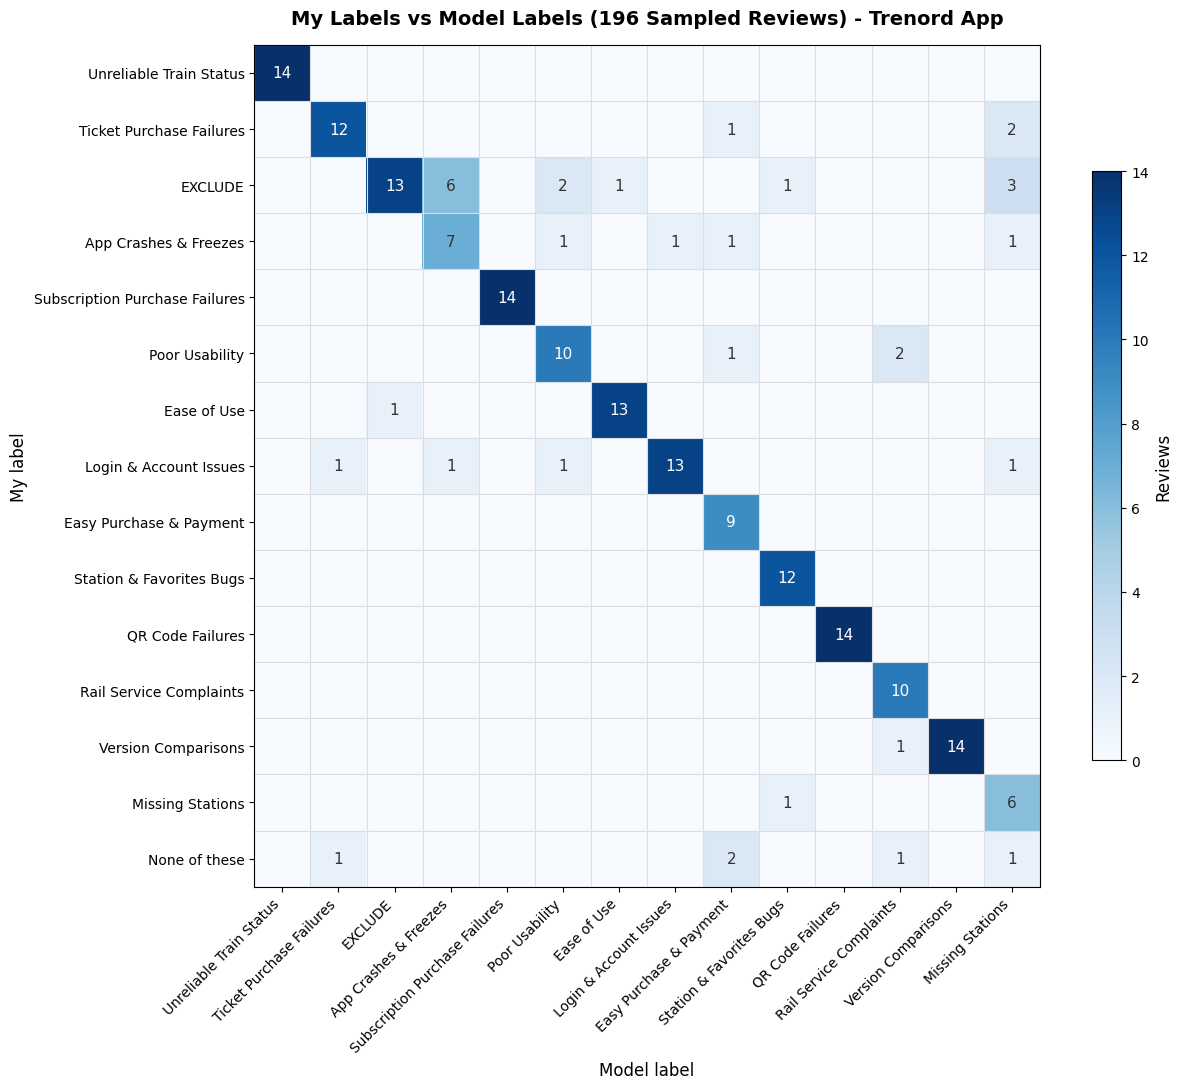

In [24]:
# --- CONFUSION MATRIX CHART ---
fig, ax = plt.subplots(figsize=(13, 11))

# A single hue, from white to dark blue: the darker the cell, the more reviews
image = ax.imshow(confusion_table.values, cmap="Blues", vmin=0)

# The count in each cell. Cells with 0 are left empty, so the disagreements stand out.
max_count = confusion_table.values.max()
for row_index in range(len(row_labels)):
    for column_index in range(len(column_labels)):
        count = confusion_table.iloc[row_index, column_index]
        if count == 0:
            continue
        # White on the dark cells, dark grey on the light ones, so every count can be read
        if count > max_count / 2:
            text_color = "white"
        else:
            text_color = "#333333"
        ax.text(column_index, row_index, str(count), ha="center", va="center", fontsize=11, color=text_color)

# Thin grey lines between the cells, so the empty ones can be followed along a row
ax.set_xticks(np.arange(len(column_labels) + 1) - 0.5, minor=True)
ax.set_yticks(np.arange(len(row_labels) + 1) - 0.5, minor=True)
ax.grid(which="minor", color="#dddddd", linewidth=0.8)
ax.tick_params(which="minor", length=0)

ax.set_xticks(range(len(column_labels)))
ax.set_xticklabels(column_labels, rotation=45, ha="right", fontsize=10)
ax.set_yticks(range(len(row_labels)))
ax.set_yticklabels(row_labels, fontsize=10)

ax.set_title(f"My Labels vs Model Labels ({len(agreement_df)} Sampled Reviews) - Trenord App",
             fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Model label", fontsize=12)
ax.set_ylabel("My label", fontsize=12)

colorbar = fig.colorbar(image, ax=ax, shrink=0.7)
colorbar.set_label("Reviews", fontsize=12)

plt.tight_layout()
plt.savefig(CONFUSION_CHART_PATH, dpi=150)
plt.show()

In [25]:
# --- THE FIVE MOST FREQUENT DISAGREEMENTS ---
# Every cell off the diagonal with at least one review, in the order of the table
disagreement_pairs = []
for my_label in row_labels:
    for model_label in column_labels:
        count = confusion_table.loc[my_label, model_label]
        if my_label != model_label and count > 0:
            disagreement_pairs.append((my_label, model_label, int(count)))

# sorted() keeps the table order between pairs with the same count, so the result is the same on every run
disagreement_pairs = sorted(disagreement_pairs, key=lambda pair: pair[2], reverse=True)

n_disagreements = len(agreement_df) - n_agree
print(f"Disagreements: {n_disagreements}, in {len(disagreement_pairs)} different pairs of labels")
print(f"Disagreements where I chose EXCLUDE      : {int(confusion_table.loc['EXCLUDE'].sum() - confusion_table.loc['EXCLUDE', 'EXCLUDE'])}")
print(f"Disagreements where I chose None of these: {int(confusion_table.loc['None of these'].sum())}")
print()
print("My label → model label: reviews")
for my_label, model_label, count in disagreement_pairs[:5]:
    print(f"  {my_label} → {model_label}: {count}")

# The fifth count may be shared by pairs that are not shown
fifth_count = disagreement_pairs[4][2]
n_tied_not_shown = 0
for my_label, model_label, count in disagreement_pairs[5:]:
    if count == fifth_count:
        n_tied_not_shown += 1
print()
print(f"Pairs not shown with the same count as the fifth ({fifth_count}): {n_tied_not_shown}")

Disagreements: 35, in 24 different pairs of labels
Disagreements where I chose EXCLUDE      : 13
Disagreements where I chose None of these: 5

My label → model label: reviews
  EXCLUDE → App Crashes & Freezes: 6
  EXCLUDE → Missing Stations: 3
  Ticket Purchase Failures → Missing Stations: 2
  EXCLUDE → Poor Usability: 2
  Poor Usability → Rail Service Complaints: 2

Pairs not shown with the same count as the fifth (2): 1


### The disagreements file

To study the disagreements I need to read the reviews, so every disagreement is written with its text to `labeling/validation_disagreements.csv`. The file is in `labeling/`, which is gitignored, and nothing of it is printed here.

In [26]:
# --- WRITE THE DISAGREEMENTS FOR MY STUDY ---
# The text comes from the coding sheet: the review as I read it while coding
disagreement_df = coding_df[["sample_id", "text"]].merge(agreement_df, on="sample_id", how="inner", validate="one_to_one")
disagreement_df = disagreement_df[disagreement_df["my_label"] != disagreement_df["model_label"]]
disagreement_df = disagreement_df[["sample_id", "text", "my_label", "model_label"]].sort_values("sample_id")

disagreement_df.to_csv(DISAGREEMENTS_PATH, index=False, encoding="utf-8-sig")

print(f"Rows written to labeling/validation_disagreements.csv: {len(disagreement_df)}")

Rows written to labeling/validation_disagreements.csv: 35


### Reading the agreement

- Cohen's kappa is 0.808 (95% CI 0.759 to 0.857). On the scale of Landis and Koch (1977) it sits on the border between "substantial" (0.61 to 0.80) and "almost perfect" (0.81 to 1.00), and its interval covers both bands. The scale is a convention: the two authors chose the bands by judgment. It gives a name to a number, it is not a test.
- The raw agreement, 82.1% (95% CI 77.6% to 86.7%), and the kappa describe the 196 sampled reviews, where each of the 14 model labels weighs the same. The weighted agreement, 86.4% (95% CI 81.6% to 90.9%), estimates the agreement on all 6,951 reviews. It is higher because most reviews are in labels with a high precision: Unreliable Train Status 100.0%, Ticket Purchase Failures 85.7%, EXCLUDE 92.9%. The lowest, Missing Stations with 42.9%, holds 71 reviews.
- 13 of the 35 disagreements are reviews I coded EXCLUDE while the model gave them a specific label. The most frequent pair is EXCLUDE → App Crashes & Freezes, 6 reviews: only 7 of the 14 App Crashes & Freezes reviews are confirmed. Then EXCLUDE → Missing Stations, 3 reviews. So most disagreements are about the line between a generic verdict and a specific problem.
- Missing Stations is the most mixed label: 6 of its 14 reviews are confirmed, and the other 8 go to five different labels, 3 of them to EXCLUDE and 2 to Ticket Purchase Failures.
- Four pairs have 2 reviews each and share the third place. The list above shows three of them in the order of the table; the fourth is None of these → Easy Purchase & Payment.

The limits of this comparison:

- There is one coder, and it is me, who also wrote the labels and the codebook. The agreement shows that the labels match how their author reads the reviews, not that another person would read them the same way. That would need a second coder.
- The coding was blind to the model label of each review, but not to the labeling work done earlier in 07: I had read the keywords and many reviews of each topic, so my idea of each label was already shaped by the model.
- The confidence intervals describe sampling uncertainty only: how much the numbers would change with another sample drawn in the same way. They do not include the uncertainty of my judgment or of the codebook definitions.
- With 14 reviews per label, the precision of each label is rough: one review moves it by 1 in 14.